# Analysis — prompting shots (0 / 1 / 3 examples)

Does a fine-tuned model do better when the prompt also contains training examples? Every model is compared with
0, 1 and 3 examples in the prompt (1 shot = the first of the 3 few-shot examples).

| Model | 0 shots | 1 shot | 3 shots |
|---|---|---|---|
| vanilla 7B | `vanilla` | `vanilla-1shot` | `few-shot` |
| Qwen 14B | `qwen-14b` | `qwen-14b-1shot` | `qwen-14b-3shot` |
| LoRA (seeds 42, 43, 44) | `lora/seed-*` | `lora-1shot/seed-*` | `lora-3shot/seed-*` |
| QLoRA (seeds 42, 43, 44) | `qlora/seed-*` | `qlora-1shot/seed-*` | `qlora-3shot/seed-*` |
| LoRA hyperparameter variants (seed 42) | `hp-lora-<c>/seed-42` | `hp-lora-<c>-1shot/seed-42` | `hp-lora-<c>-3shot/seed-42` |

Same units, seed aggregation and tests as `experiment/experiment/analysis/index.ipynb`: structural metrics per unique
test instruction (median of duplicate rows, median of seeds), DS-1000 Pass@1 / Pass@10 as binary values per problem
(majority of seeds); Friedman / Cochran's Q, then Wilcoxon / McNemar with Holm correction and paired bootstrap CIs.
Cells whose runs are not on the Hub yet are skipped. Structural results need `code4ml_ratings.csv`
(`experiment/experiment/rating/rate_outputs.ipynb`).

In [14]:
%pip install -q pandas scipy statsmodels huggingface_hub matplotlib   # into the selected kernel (Colab or local)

import os

try:  # Colab secret; elsewhere an existing `hf auth login` is used
    from google.colab import userdata
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
except Exception:
    pass


[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Runs and helpers

In [15]:
import itertools
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import HfApi, hf_hub_download
from scipy import stats
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar
from statsmodels.stats.multitest import multipletests

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

REPO = 'dimsmauls/code4ml-eval-outputs'
SEEDS = (42, 43, 44)
SHOTS = (0, 1, 3)
ALPHA = 0.05
BOOTSTRAP = 10_000
SEED = 42

# model -> ({shots: run name}, seeds); seeds None = one run without a seed folder
MODELS = {
    'vanilla': ({0: 'vanilla', 1: 'vanilla-1shot', 3: 'few-shot'}, None),
    'qwen-14b': ({0: 'qwen-14b', 1: 'qwen-14b-1shot', 3: 'qwen-14b-3shot'}, None),
    'lora': ({0: 'lora', 1: 'lora-1shot', 3: 'lora-3shot'}, SEEDS),
    'qlora': ({0: 'qlora', 1: 'qlora-1shot', 3: 'qlora-3shot'}, SEEDS),
    **{f'hp-lora-{c}': ({0: f'hp-lora-{c}', 1: f'hp-lora-{c}-1shot', 3: f'hp-lora-{c}-3shot'}, (42,))
       for c in ('cosine', 'r32', 'lr1e-4')},
}
CELLS = {(model, k): ([name] if seeds is None else [f'{name}/seed-{s}' for s in seeds])
         for model, (names, seeds) in MODELS.items() for k, name in names.items()}

files = set(HfApi().list_repo_files(REPO, repo_type='dataset'))
available = {cell: runs for cell, runs in CELLS.items() if all(f'{r}/summary.json' in files for r in runs)}
rated = {cell: runs for cell, runs in available.items() if all(f'{r}/code4ml_ratings.csv' in files for r in runs)}
print('cells on the Hub:', len(available), 'of', len(CELLS), '| rated:', len(rated))
print('missing:', sorted(set(CELLS) - set(available)) or 'none')
print('not rated yet:', sorted(set(available) - set(rated)) or 'none')


def label(cell):
    return f'{cell[0]} | {cell[1]}-shot'


def get(path):
    return hf_hub_download(REPO, path, repo_type='dataset')


# ---- same helpers as experiment/experiment/analysis/index.ipynb ----
def holm(pvalues):
    return multipletests(pvalues, method='holm')[1]


def bootstrap_ci(diffs):
    '''Paired bootstrap over units: 95% CI of the mean of per-unit differences.'''
    diffs = np.asarray(diffs, dtype=float)
    rng = np.random.default_rng(SEED)
    means = diffs[rng.integers(0, len(diffs), (BOOTSTRAP, len(diffs)))].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def friedman(table, columns):
    block = table[columns].dropna()
    chi2, p = stats.friedmanchisquare(*(block[c] for c in columns))
    return {'n': len(block), 'chi2': chi2, 'p': p, 'kendall_w': chi2 / (len(block) * (len(columns) - 1))}


def wilcoxon_family(table, pairs):
    rows = []
    for a, b in pairs:
        diff = (table[a] - table[b]).dropna()
        nonzero = diff[diff != 0]
        if len(nonzero):
            p = stats.wilcoxon(nonzero).pvalue
            ranks = stats.rankdata(nonzero.abs())
            r = (ranks[nonzero.to_numpy() > 0].sum() - ranks[nonzero.to_numpy() < 0].sum()) / ranks.sum()
        else:
            p, r = 1.0, 0.0
        rows.append({'comparison': f'{a} − {b}', 'n': len(diff), 'median_diff': diff.median(),
                     'mean_diff': diff.mean(), 'p': p, 'rank_biserial': r})
    out = pd.DataFrame(rows)
    out['p_holm'] = holm(out['p'])
    out['significant'] = out['p_holm'] < ALPHA
    return out


def mcnemar_family(table, pairs):
    rows = []
    for a, b in pairs:
        block = table[[a, b]].dropna().astype(int)
        both, only_a = ((block[a] == 1) & (block[b] == 1)).sum(), ((block[a] == 1) & (block[b] == 0)).sum()
        only_b, neither = ((block[a] == 0) & (block[b] == 1)).sum(), ((block[a] == 0) & (block[b] == 0)).sum()
        p = mcnemar([[both, only_a], [only_b, neither]], exact=True).pvalue
        low, high = bootstrap_ci(block[a] - block[b])
        rows.append({'comparison': f'{a} − {b}', 'n': len(block), 'rate_a': block[a].mean(), 'rate_b': block[b].mean(),
                     'diff': block[a].mean() - block[b].mean(), 'ci95_low': low, 'ci95_high': high,
                     'a_only': only_a, 'b_only': only_b, 'p': p})
    out = pd.DataFrame(rows)
    out['p_holm'] = holm(out['p'])
    out['significant'] = out['p_holm'] < ALPHA
    return out


def combine(frames, how):
    '''One value per unit for a cell: median of the seeds, only units present in every seed.'''
    if len(frames) == 1:
        return frames[0]
    stacked = pd.concat(frames, keys=range(len(frames)))
    median = stacked.groupby(level=1).median()
    complete = stacked.groupby(level=1).count() == len(frames)
    return how(median.where(complete))

cells on the Hub: 21 of 21 | rated: 21
missing: none
not rated yet: none


## 2. Load ratings and DS-1000 results

In [16]:
GRADE = {g: i for i, g in enumerate('ABCDE', 1)}
STRUCTURAL = ['maintainability', 'code_smells', 'complexity', 'cognitive_complexity', 'bugs', 'mlscent_ml_rating',
              'code_smells_per_100_ncloc', 'has_import']


def has_import(code):
    return float(any(line.lstrip().startswith(('import ', 'from ')) for line in str(code).splitlines()))


def load_ratings(run):
    '''Same as analysis/index.ipynb (SonarQube N/A without ncloc), plus has_import (1 = the answer imports something).'''
    df = pd.read_csv(get(f'{run}/code4ml_ratings.csv'), dtype={'id': str})
    valid = df['ast_valid'].astype(str) == 'True'
    ncloc = pd.to_numeric(df['ncloc'], errors='coerce')
    sonar = valid & (ncloc > 0)
    out = pd.DataFrame(index=df['id'])
    out['ast_valid'] = valid.to_numpy()
    out['ncloc'] = ncloc.where(sonar).to_numpy()
    out['maintainability'] = df['maintainability_rating'].map(GRADE).where(sonar).to_numpy()
    for metric in ('code_smells', 'complexity', 'cognitive_complexity', 'bugs'):
        out[metric] = pd.to_numeric(df[metric], errors='coerce').where(sonar).to_numpy()
    out['mlscent_ml_rating'] = df['mlscent_ml_rating'].map(GRADE).where(valid).to_numpy()
    out['code_smells_per_100_ncloc'] = 100 * out['code_smells'] / out['ncloc']
    out['has_import'] = df['code_block'].map(has_import).where(valid).to_numpy()
    return out


# unit of the structural tests = unique test instruction (304 rows share 40 instruction texts)
INSTRUCTION_OF = pd.read_csv(get('vanilla/code4ml_ratings.csv'), dtype={'id': str}).set_index('id')['graph_vertex_subclass']


def by_instruction(df):
    return df.drop(columns='ast_valid').groupby(INSTRUCTION_OF.reindex(df.index).to_numpy()).median()


def ds1000_binary(run):
    res = pd.read_json(get(f'{run}/ds1000_results.jsonl'), lines=True)
    first = res[res['sample'] == 0].set_index('problem_id')['passed'].astype(float)
    any_pass = res.groupby('problem_id')['passed'].any().astype(float)
    return pd.DataFrame({'pass1': first, 'pass10': any_pass})


ratings = {r: load_ratings(r) for runs in rated.values() for r in runs}
struct = {cell: combine([by_instruction(ratings[r]) for r in runs], lambda df: df) for cell, runs in rated.items()}
binary = {cell: combine([ds1000_binary(r) for r in runs], lambda df: df.round()) for cell, runs in available.items()}
summaries = {r: json.load(open(get(f'{r}/summary.json'))) for runs in available.values() for r in runs}
print('loaded', len(summaries), 'runs')

loaded 33 runs


## 3. Matrices (model × shots)
Pass@k: unbiased estimate, mean of seeds. Structural: mean over unique instructions (LoRA / QLoRA: median of seeds
first). `has_import`: share of instructions whose answer imports something.

In [17]:
def matrix(value, cells):
    return pd.DataFrame({f'{k}-shot': {m: value((m, k)) if (m, k) in cells else np.nan for m in MODELS}
                         for k in SHOTS})


for k in ('pass@1', 'pass@10'):
    print(f'\n=== DS-1000 {k}')
    display(matrix(lambda cell: np.mean([summaries[r]['ds1000'][k] for r in available[cell]]), available).round(4))

for metric in ['ncloc'] + STRUCTURAL:
    how = (lambda cell: struct[cell][metric].median()) if metric == 'ncloc' else (lambda cell: struct[cell][metric].mean())
    print(f"\n=== {'median' if metric == 'ncloc' else 'mean'} {metric}")
    display(matrix(how, struct).round(3))


=== DS-1000 pass@1


,0-shot,1-shot,3-shot
vanilla,0.3634,0.4173,0.4470
qwen-14b,0.2757,0.4804,0.5303
lora,0.3143,0.3342,0.3759
qlora,0.3159,0.3356,0.3787
hp-lora-cosine,0.3086,0.3289,0.3801
hp-lora-r32,0.3247,0.3366,0.3768
hp-lora-lr1e-4,0.3223,0.3475,0.3914



=== DS-1000 pass@10


,0-shot,1-shot,3-shot
vanilla,0.6620,0.6489,0.6680
qwen-14b,0.5416,0.7242,0.7392
lora,0.6138,0.6316,0.6777
qlora,0.6185,0.6302,0.6734
hp-lora-cosine,0.5968,0.6169,0.6851
hp-lora-r32,0.6108,0.6199,0.6861
hp-lora-lr1e-4,0.6399,0.6520,0.6911



=== median ncloc


...

,0-shot,1-shot,3-shot
vanilla,1.588,1.688,2.250
qwen-14b,1.618,1.297,1.000
lora,1.200,1.625,1.714
qlora,1.000,1.571,1.714
hp-lora-cosine,1.200,1.700,2.111
hp-lora-r32,1.300,1.800,1.800
hp-lora-lr1e-4,1.375,1.889,2.500



=== mean code_smells_per_100_ncloc


,0-shot,1-shot,3-shot
vanilla,2.075,0.628,1.458
qwen-14b,1.693,6.029,0.000
lora,3.022,6.670,7.278
qlora,3.083,5.979,6.923
hp-lora-cosine,1.964,5.524,11.536
hp-lora-r32,2.859,6.729,9.744
hp-lora-lr1e-4,2.312,6.086,6.472



=== mean has_import


,0-shot,1-shot,3-shot
vanilla,0.923,0.550,0.250
qwen-14b,0.975,1.000,0.025
lora,0.205,0.256,0.231
qlora,0.179,0.200,0.205
hp-lora-cosine,0.250,0.275,0.256
hp-lora-r32,0.250,0.275,0.282
hp-lora-lr1e-4,0.200,0.225,0.150


In [18]:
# Pass@k per seed (descriptive only)
pd.DataFrame([{'cell': label(cell), 'run': r, 'pass@1': summaries[r]['ds1000']['pass@1'],
               'pass@10': summaries[r]['ds1000']['pass@10']}
              for cell, runs in available.items() if len(runs) > 1 for r in runs]).set_index(['cell', 'run']).round(4)

pass@1  pass@10
cell           run                                 
lora | 0-shot  lora/seed-42         0.3168   0.6179
               lora/seed-43         0.3086   0.6058
               lora/seed-44         0.3175   0.6179
lora | 1-shot  lora-1shot/seed-42   0.3330   0.6249
               lora-1shot/seed-43   0.3252   0.6269
               lora-1shot/seed-44   0.3445   0.6429
lora | 3-shot  lora-3shot/seed-42   0.3808   0.6830
               lora-3shot/seed-43   0.3668   0.6700
               lora-3shot/seed-44   0.3801   0.6800
qlora | 0-shot qlora/seed-42        0.3158   0.6229
               qlora/seed-43        0.3152   0.6138
               qlora/seed-44        0.3166   0.6189
qlora | 1-shot qlora-1shot/seed-42  0.3348   0.6339
               qlora-1shot/seed-43  0.3297   0.6259
               qlora-1shot/seed-44  0.3422   0.6309
qlora | 3-shot qlora-3shot/seed-42  0.3811   0.6710
               qlora-3shot/seed-43  0.3730   0.6730
               qlora-3shot/seed-44  0.3818   0.6760

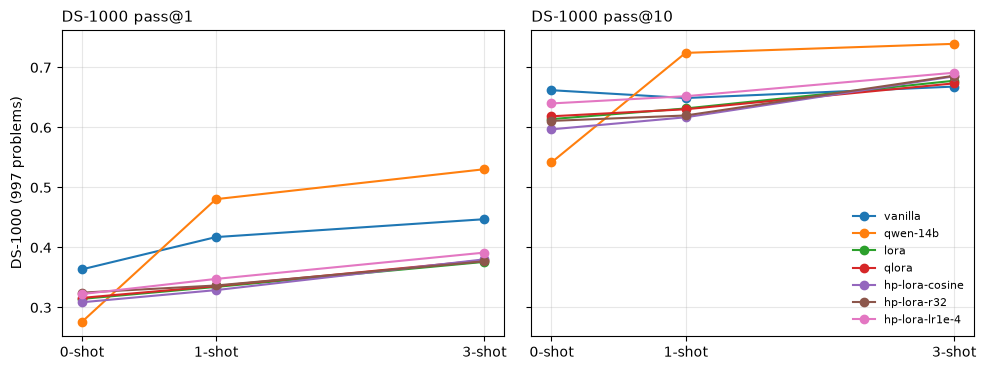

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, k in zip(axes, ('pass@1', 'pass@10')):
    for model in MODELS:
        points = [(s, np.mean([summaries[r]['ds1000'][k] for r in available[(model, s)]]))
                  for s in SHOTS if (model, s) in available]
        if points:
            ax.plot(*zip(*points), marker='o', linewidth=1.5, label=model)
    ax.set_xticks(SHOTS, [f'{s}-shot' for s in SHOTS])
    ax.set_title(f'DS-1000 {k}', loc='left', fontsize=11)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('DS-1000 (997 problems)')
axes[1].legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

=== maintainability: % of instructions rated A


,0-shot,1-shot,3-shot
vanilla,100.0,100.0,97.5
qwen-14b,100.0,92.3,100.0
lora,97.4,92.3,92.3
qlora,97.4,92.5,92.3
hp-lora-cosine,97.5,92.5,92.3
hp-lora-r32,95.0,92.5,89.7
hp-lora-lr1e-4,97.5,92.5,92.5


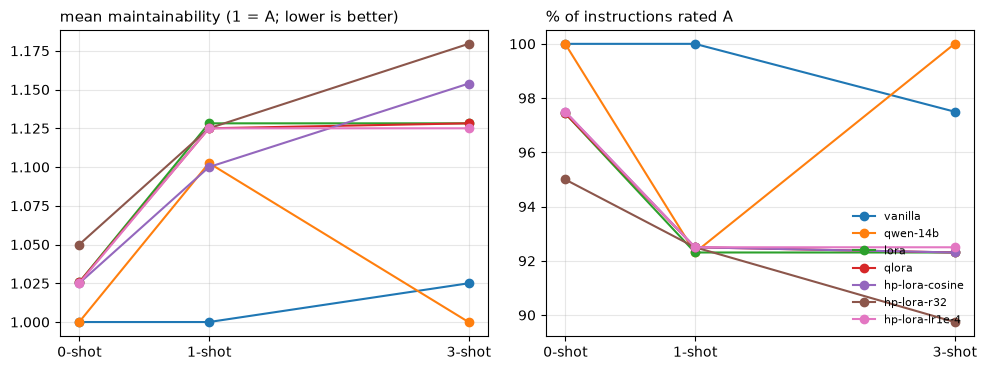

In [20]:
# Maintainability (SonarQube) per model and shot level: share of instructions rated A, as reported in the thesis,
# and the mean rating (1 = A ... 5 = E, lower is better). Needs code4ml_ratings.csv for the cell.
def share_a(cell):
    rating = struct[cell]['maintainability'].dropna()
    return 100 * (rating == 1).mean() if len(rating) else np.nan


print('=== maintainability: % of instructions rated A')
display(matrix(share_a, struct).round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
panels = (('mean maintainability (1 = A; lower is better)', lambda cell: struct[cell]['maintainability'].mean()),
          ('% of instructions rated A', share_a))
for ax, (title, value) in zip(axes, panels):
    for model in MODELS:
        points = [(s, value((model, s))) for s in SHOTS if (model, s) in struct]
        if points:
            ax.plot(*zip(*points), marker='o', linewidth=1.5, label=model)
    ax.set_xticks(SHOTS, [f'{s}-shot' for s in SHOTS])
    ax.set_title(title, loc='left', fontsize=11)
    ax.grid(alpha=0.3)
axes[1].legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

## 4. Within each model: 0 vs 1 vs 3 shots
Cochran's Q (DS-1000) / Friedman (structural) over the available shot levels, then McNemar / Wilcoxon for every pair
of shot levels with Holm correction inside the model. With only two shot levels the pair is tested directly.

In [21]:
def across_shots(model):
    print(f'\n########## {model} ##########')
    cells = [(model, s) for s in SHOTS if (model, s) in available]
    if len(cells) < 2:
        print('fewer than two shot levels on the Hub: skipped')
        return
    for k in ('pass1', 'pass10'):
        table = pd.DataFrame({label(c): binary[c][k] for c in cells})
        if len(cells) >= 3:
            block = table.dropna()
            q = cochrans_q(block.to_numpy())
            print(f"=== {k} | Cochran's Q n={len(block)} Q={q.statistic:.3f} p={q.pvalue:.4g}")
            if q.pvalue >= ALPHA:
                print('not significant: no post-hoc')
                continue
        display(mcnemar_family(table, list(itertools.combinations(table.columns, 2))).round(4))
    cells = [c for c in cells if c in struct]
    if len(cells) < 2:
        print('structural: fewer than two rated shot levels, skipped')
        return
    for metric in STRUCTURAL:
        table = pd.DataFrame({label(c): struct[c][metric] for c in cells})
        if table.dropna().nunique().max() <= 1:
            print(f'=== {metric}: all values equal, nothing to test')
            continue
        if len(cells) >= 3:
            omnibus = friedman(table, list(table.columns))
            print(f"=== {metric} | Friedman n={omnibus['n']} chi2={omnibus['chi2']:.3f} p={omnibus['p']:.4g} "
                  f"Kendall's W={omnibus['kendall_w']:.3f}")
            if omnibus['p'] >= ALPHA:
                continue
        else:
            print(f'=== {metric}')
        display(wilcoxon_family(table, list(itertools.combinations(table.columns, 2))).round(4))


for model in MODELS:
    across_shots(model)


########## vanilla ##########
=== pass1 | Cochran's Q n=997 Q=24.875 p=3.967e-06


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,vanilla | 0-shot − vanilla | 1-shot,997,0.3721,0.4343,-0.0622,-0.0913,-0.0331,87,149,0.0001,0.0001,True
1,vanilla | 0-shot − vanilla | 3-shot,997,0.3721,0.4393,-0.0672,-0.0973,-0.0371,91,158,0.0000,0.0001,True
2,vanilla | 1-shot − vanilla | 3-shot,997,0.4343,0.4393,-0.0050,-0.0321,0.0221,91,96,0.7700,0.7700,False


=== pass10 | Cochran's Q n=997 Q=2.708 p=0.2582
not significant: no post-hoc
=== maintainability | Friedman n=39 chi2=2.000 p=0.3679 Kendall's W=0.026
=== code_smells | Friedman n=39 chi2=6.200 p=0.04505 Kendall's W=0.079


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,vanilla | 0-shot − vanilla | 1-shot,39,0.0,0.1795,0.1133,0.6444,0.2266,False
1,vanilla | 0-shot − vanilla | 3-shot,39,0.0,0.2051,0.0547,0.8056,0.1641,False
2,vanilla | 1-shot − vanilla | 3-shot,40,0.0,0.0250,1.0000,0.3333,1.0000,False


=== complexity | Friedman n=39 chi2=8.400 p=0.015 Kendall's W=0.108


...

=== cognitive_complexity | Friedman n=40 chi2=8.000 p=0.01832 Kendall's W=0.100


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,hp-lora-lr1e-4 | 0-shot − hp-lora-lr1e-4 | 1-shot,40,0.0,0.2,0.125,1.0,0.375,False
1,hp-lora-lr1e-4 | 0-shot − hp-lora-lr1e-4 | 3-shot,40,0.0,0.2,0.125,1.0,0.375,False
2,hp-lora-lr1e-4 | 1-shot − hp-lora-lr1e-4 | 3-shot,40,0.0,0.0,1.000,0.0,1.000,False


=== bugs | Friedman n=40 chi2=1.000 p=0.6065 Kendall's W=0.013
=== mlscent_ml_rating | Friedman n=5 chi2=6.615 p=0.0366 Kendall's W=0.662


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,hp-lora-lr1e-4 | 0-shot − hp-lora-lr1e-4 | 1-shot,8,0.0,-0.25,0.500,-1.0,0.500,False
1,hp-lora-lr1e-4 | 0-shot − hp-lora-lr1e-4 | 3-shot,5,-1.0,-1.00,0.125,-1.0,0.375,False
2,hp-lora-lr1e-4 | 1-shot − hp-lora-lr1e-4 | 3-shot,5,-1.0,-0.60,0.250,-1.0,0.500,False


=== code_smells_per_100_ncloc | Friedman n=40 chi2=1.909 p=0.385 Kendall's W=0.024
=== has_import | Friedman n=40 chi2=2.800 p=0.2466 Kendall's W=0.035


## 5. Within each shot level: models compared
Same families as the main analysis: LoRA / QLoRA against vanilla and against each other, and Qwen 14B against LoRA,
QLoRA and vanilla 7B (separate Holm family). At 3 shots, vanilla is the existing few-shot arm, so this answers whether
fine-tuning plus examples beats examples alone.

In [22]:
FAMILIES = {'main': [('lora', 'vanilla'), ('qlora', 'vanilla'), ('lora', 'qlora')],
            '14b': [('qwen-14b', 'lora'), ('qwen-14b', 'qlora'), ('qwen-14b', 'vanilla')]}

for s in SHOTS:
    for family, model_pairs in FAMILIES.items():
        pairs = [(label((a, s)), label((b, s))) for a, b in model_pairs if (a, s) in available and (b, s) in available]
        if not pairs:
            continue
        print(f'\n########## {s}-shot, family {family} ##########')
        for k in ('pass1', 'pass10'):
            table = pd.DataFrame({label(c): binary[c][k] for c in available if c[1] == s})
            print(f'=== {k}')
            display(mcnemar_family(table, pairs).round(4))
        rated_pairs = [(a, b) for a, b in pairs if all(c in map(label, struct) for c in (a, b))]
        for metric in STRUCTURAL if rated_pairs else []:
            table = pd.DataFrame({label(c): struct[c][metric] for c in struct if c[1] == s})
            print(f'=== {metric}')
            display(wilcoxon_family(table, rated_pairs).round(4))


########## 0-shot, family main ##########
=== pass1


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,lora | 0-shot − vanilla | 0-shot,997,0.3089,0.3721,-0.0632,-0.0923,-0.0341,83,146,0.00,0.0001,True
1,qlora | 0-shot − vanilla | 0-shot,997,0.3039,0.3721,-0.0682,-0.0983,-0.0371,90,158,0.00,0.0001,True
2,lora | 0-shot − qlora | 0-shot,997,0.3089,0.3039,0.0050,-0.0120,0.0221,39,34,0.64,0.6400,False


=== pass10


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,lora | 0-shot − vanilla | 0-shot,997,0.6128,0.6620,-0.0491,-0.0752,-0.0231,66,115,0.0003,0.0007,True
1,qlora | 0-shot − vanilla | 0-shot,997,0.6118,0.6620,-0.0502,-0.0752,-0.0251,60,110,0.0002,0.0005,True
2,lora | 0-shot − qlora | 0-shot,997,0.6128,0.6118,0.0010,-0.0160,0.0181,38,37,1.0000,1.0000,False


=== maintainability


...

,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b | 3-shot − lora | 3-shot,0,NaN,NaN,1.0,0.0,1.0,False
1,qwen-14b | 3-shot − qlora | 3-shot,0,NaN,NaN,1.0,0.0,1.0,False
2,qwen-14b | 3-shot − vanilla | 3-shot,1,0.0,0.0,1.0,0.0,1.0,False


=== code_smells_per_100_ncloc


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b | 3-shot − lora | 3-shot,39,0.0,-7.2778,0.0312,-1.0,0.0938,False
1,qwen-14b | 3-shot − qlora | 3-shot,39,0.0,-6.9231,0.0625,-1.0,0.1250,False
2,qwen-14b | 3-shot − vanilla | 3-shot,40,0.0,-1.4583,0.5000,-1.0,0.5000,False


=== has_import


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b | 3-shot − lora | 3-shot,39,0.0,-0.2051,0.0215,-0.8000,0.0430,True
1,qwen-14b | 3-shot − qlora | 3-shot,39,0.0,-0.1795,0.0391,-0.7778,0.0430,True
2,qwen-14b | 3-shot − vanilla | 3-shot,40,0.0,-0.2250,0.0039,-1.0000,0.0117,True
